<a href="https://colab.research.google.com/github/HAMMEDTAIWONURUDEEN/Breast_Cancer_prediction/blob/main/heartAttack.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fatemehmohammadinia/heart-attack-dataset-tarik-a-rashid")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heart-attack-dataset-tarik-a-rashid' dataset.
Path to dataset files: /kaggle/input/heart-attack-dataset-tarik-a-rashid


In [57]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
csv_path = os.path.join(path, "Medicaldataset.csv")
df = pd.read_csv(csv_path)
df

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative
...,...,...,...,...,...,...,...,...,...
1314,44,1,94,122,67,204.0,1.63,0.006,negative
1315,66,1,84,125,55,149.0,1.33,0.172,positive
1316,45,1,85,168,104,96.0,1.24,4.250,positive
1317,54,1,58,117,68,443.0,5.80,0.359,positive


In [58]:
df.columns

Index(['Age', 'Gender', 'Heart rate', 'Systolic blood pressure',
       'Diastolic blood pressure', 'Blood sugar', 'CK-MB', 'Troponin',
       'Result'],
      dtype='object')

In [59]:
df.dtypes

,0
Age,int64
Gender,int64
Heart rate,int64
Systolic blood pressure,int64
Diastolic blood pressure,int64
Blood sugar,float64
CK-MB,float64
Troponin,float64
Result,object


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1319 non-null   int64  
 1   Gender                    1319 non-null   int64  
 2   Heart rate                1319 non-null   int64  
 3   Systolic blood pressure   1319 non-null   int64  
 4   Diastolic blood pressure  1319 non-null   int64  
 5   Blood sugar               1319 non-null   float64
 6   CK-MB                     1319 non-null   float64
 7   Troponin                  1319 non-null   float64
 8   Result                    1319 non-null   object 
dtypes: float64(3), int64(5), object(1)
memory usage: 92.9+ KB


In [61]:
df.value_counts()

Age  Gender  Heart rate  Systolic blood pressure  Diastolic blood pressure  Blood sugar  CK-MB    Troponin  Result  
14   0       89          111                      57                        133.0        2.620    0.012     negative    1
19   0       62          114                      69                        240.0        300.000  0.004     positive    1
             70          117                      76                        91.0         36.240   0.025     positive    1
     1       68          116                      74                        99.0         0.606    0.003     negative    1
20   1       60          156                      60                        103.0        5.220    1.840     positive    1
                                                                                                                       ..
90   1       59          164                      75                        415.0        5.870    0.014     negative    1
91   1       80          65                       53                        94.0         5.370    0.013     negative    1
100  1       60          209                      75                        329.0        5.660    0.840     positive    1
103  0       56          171                      56                        150.0        51.960   0.044     positive    1
             86          146                      92                        120.0        69.320   0.059     positive    1
Name: count, Length: 1319, dtype: int64

In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
df.isnull().sum()

,0
Age,0
Gender,0
Heart rate,0
Systolic blood pressure,0
Diastolic blood pressure,0
Blood sugar,0
CK-MB,0
Troponin,0
Result,0


In [64]:
df["Result"] = df["Result"].map({
    "positive":"1",
    "negative":"0"
})
df["Result"] = pd.to_numeric(df["Result"],errors="coerce")

In [65]:
df["Result"].value_counts(normalize=True)*100

,proportion
Result,
1,61.410159
0,38.589841


In [66]:
df.describe()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
count,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000
mean,56.191812,0.659591,78.336619,127.170584,72.269143,146.634344,15.274306,0.360942,0.614102
std,13.647315,0.474027,51.630270,26.122720,14.033924,74.923045,46.327083,1.154568,0.486991
min,14.000000,0.000000,20.000000,42.000000,38.000000,35.000000,0.321000,0.001000,0.000000
25%,47.000000,0.000000,64.000000,110.000000,62.000000,98.000000,1.655000,0.006000,0.000000
50%,58.000000,1.000000,74.000000,124.000000,72.000000,116.000000,2.850000,0.014000,1.000000
75%,65.000000,1.000000,85.000000,143.000000,81.000000,169.500000,5.805000,0.085500,1.000000
max,103.000000,1.000000,1111.000000,223.000000,154.000000,541.000000,300.000000,10.300000,1.000000


In [67]:
constant_columns = df.drop(columns=["Result"]).columns[df.drop(columns=["Result"]).nunique()==1]
print(constant_columns)

Index([], dtype='object')


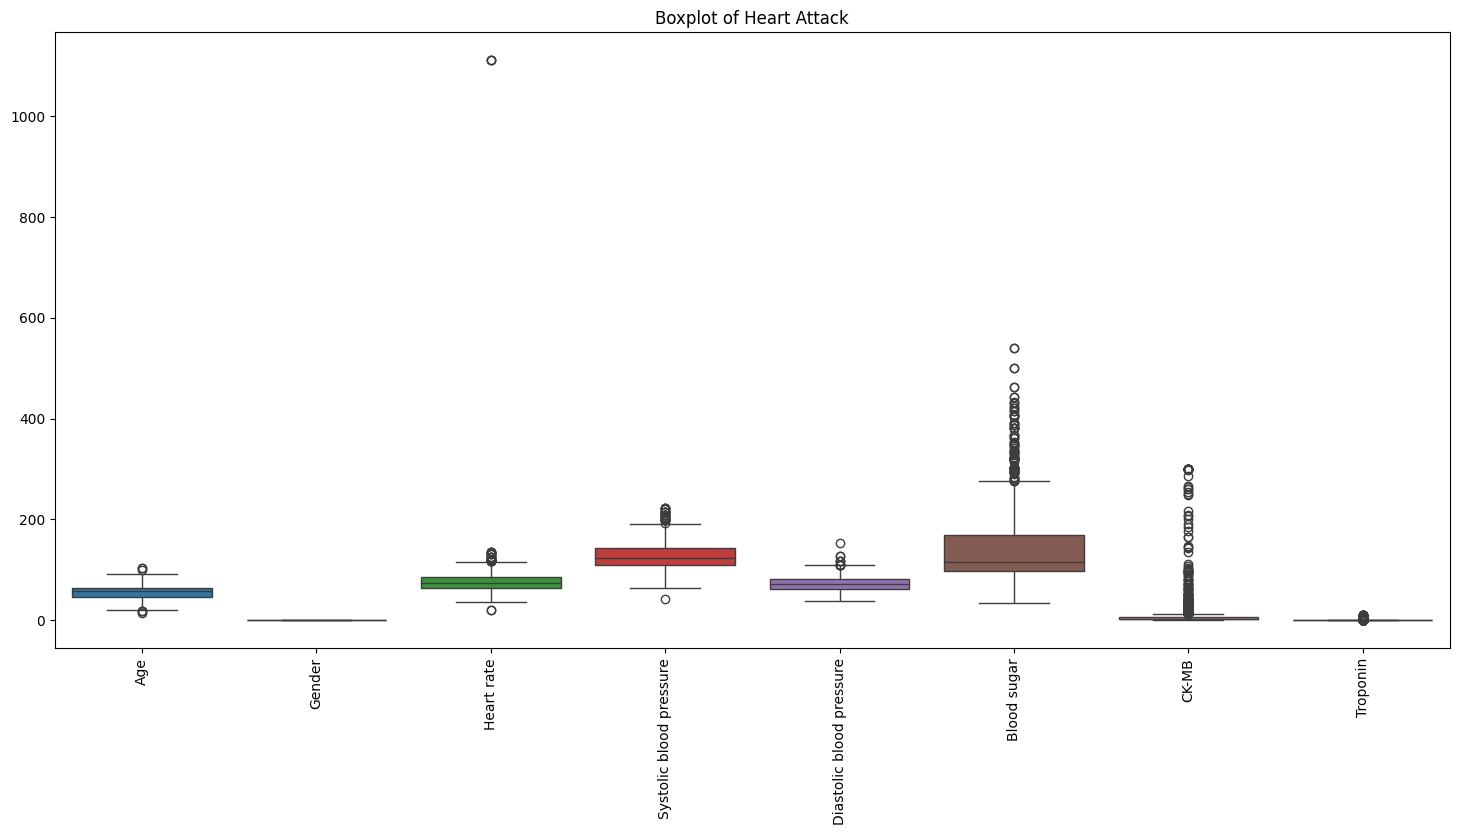

In [68]:
plt.figure(figsize=(18,8))
sns.boxplot(data=df.drop(columns=["Result"]))
plt.xticks(rotation=90)
plt.title("Boxplot of Heart Attack")
plt.show()

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Gender'}>,
        <Axes: title={'center': 'Heart rate'}>],
       [<Axes: title={'center': 'Systolic blood pressure'}>,
        <Axes: title={'center': 'Diastolic blood pressure'}>,
        <Axes: title={'center': 'Blood sugar'}>],
       [<Axes: title={'center': 'CK-MB'}>,
        <Axes: title={'center': 'Troponin'}>, <Axes: >]], dtype=object)

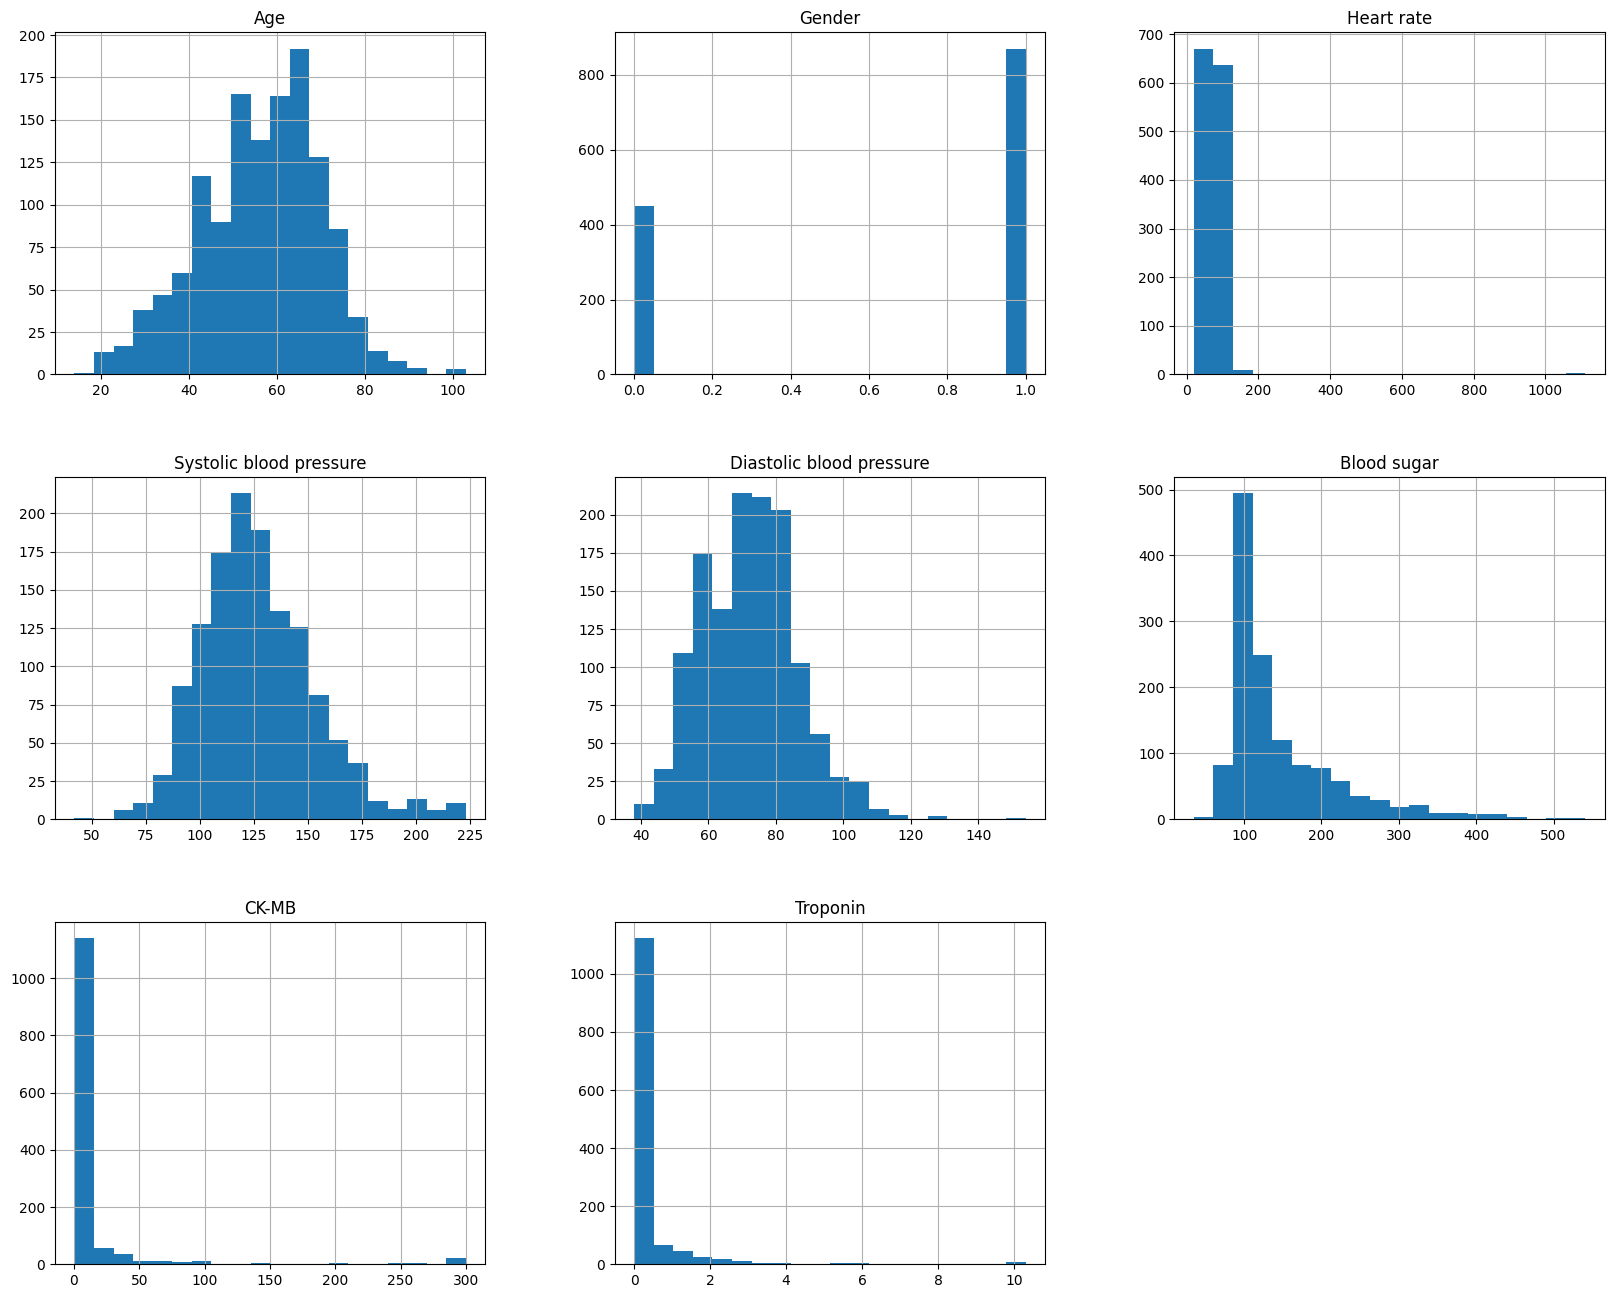

In [69]:
df.drop(columns=["Result"]).hist(figsize=(20,16),bins=20)

<Axes: >

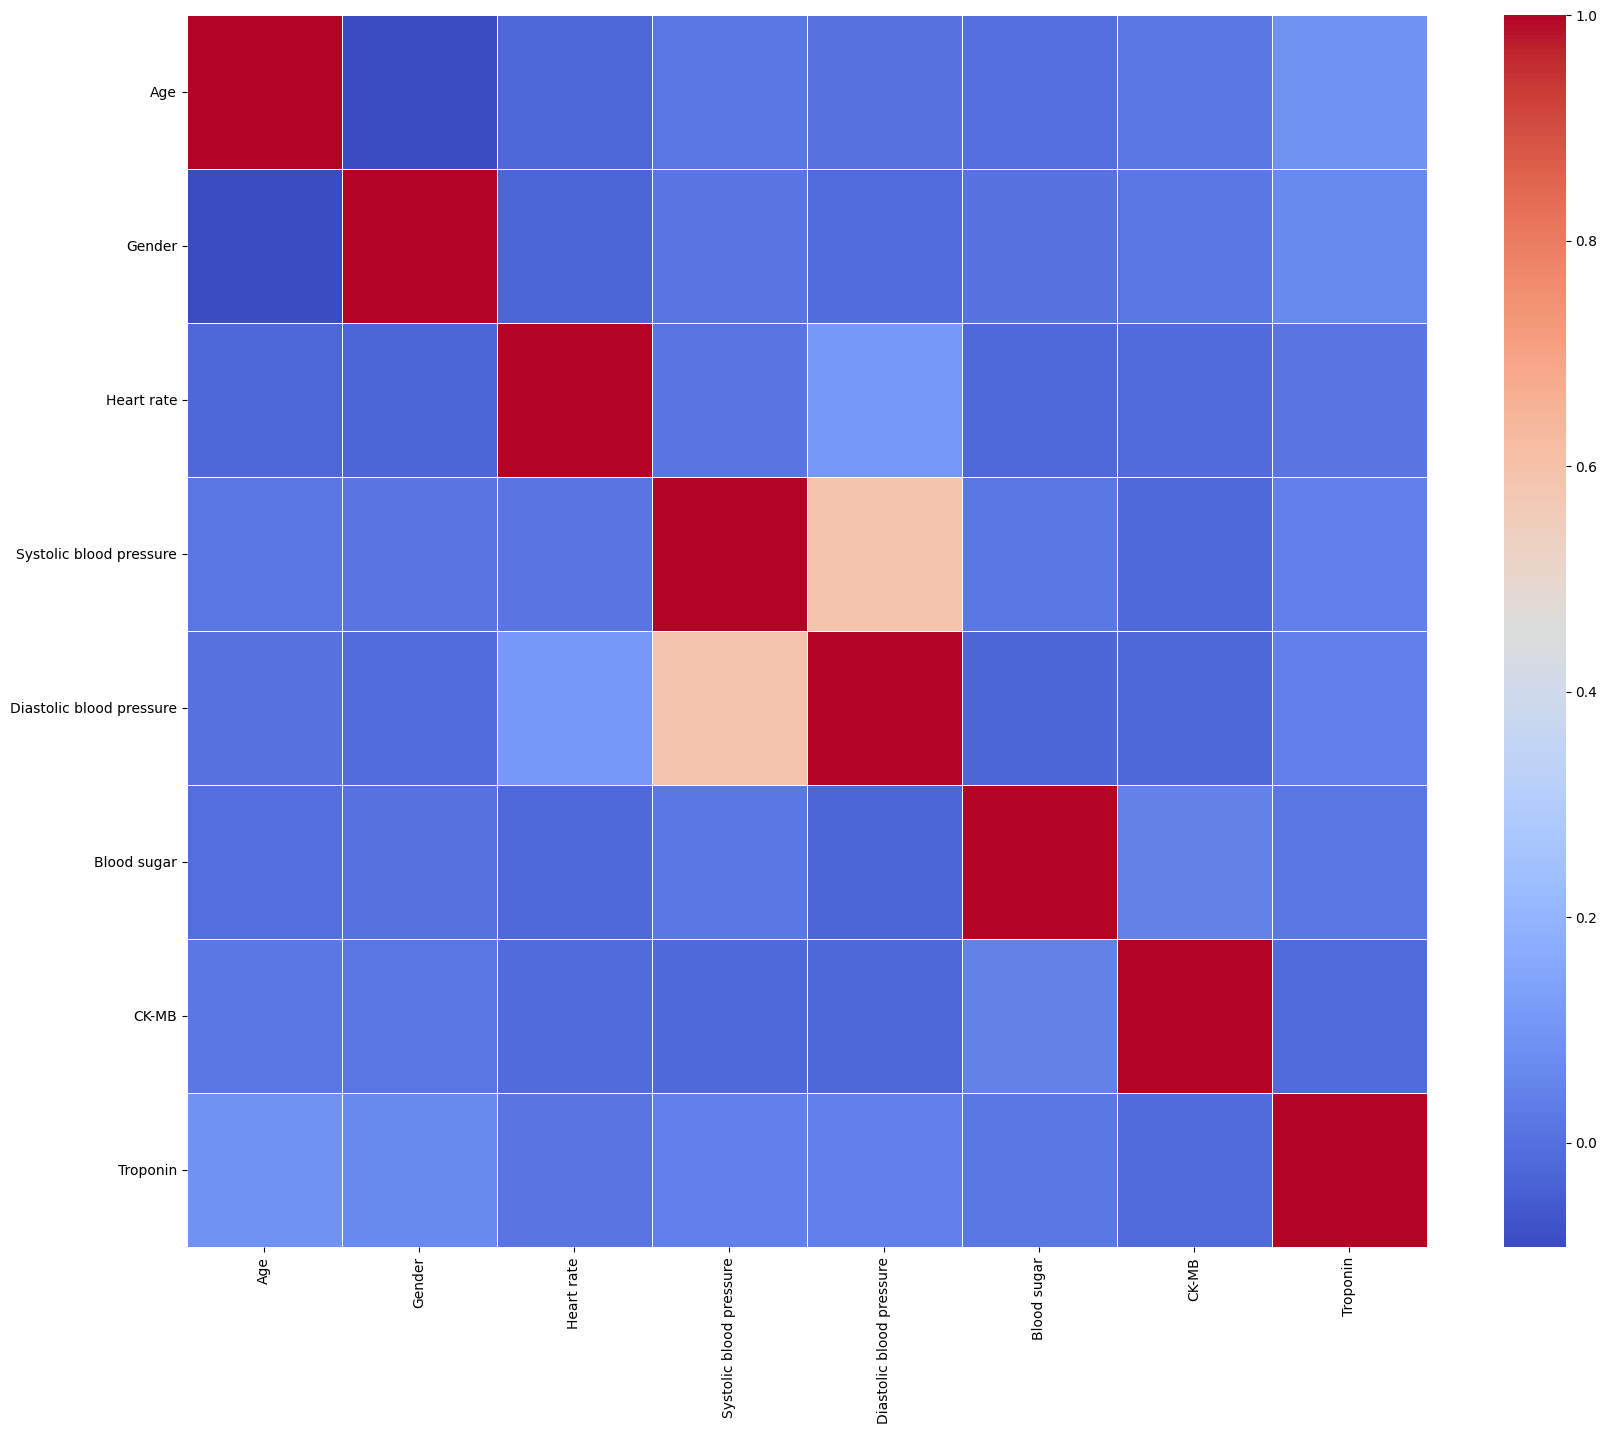

In [70]:
correlation = df.drop(columns=["Result"]).corr()
plt.figure(figsize=(20,16))
sns.heatmap(correlation,cmap="coolwarm",annot=False,linewidths=0.5)

In [71]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["Result"])
y = df["Result"]
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
print("Successfullly Splited")



Successfullly Splited


In [72]:
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=42,stratify=y_temp)
print("Successfully splited")

Successfully splited


In [73]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [74]:
model = LogisticRegression()
model.fit(X_train,y_train)
print("Model Trained")

Model Trained


In [75]:
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)
accuracy_1 = accuracy_score(y_val,y_val_pred)
accuracy_2 = accuracy_score(y_test,y_test_pred)
print("Accuracy_val:",accuracy_1)
print("Accuracy_test:",accuracy_2)

Accuracy_val: 0.7525252525252525
Accuracy_test: 0.803030303030303


In [76]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Confusion Matrix:
[[ 55  22]
 [ 17 104]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.71      0.74        77
           1       0.83      0.86      0.84       121

    accuracy                           0.80       198
   macro avg       0.79      0.79      0.79       198
weighted avg       0.80      0.80      0.80       198

Confusion Matrix:
[[53 23]
 [26 96]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.70      0.68        76
           1       0.81      0.79      0.80       122

    accuracy                           0.75       198
   macro avg       0.74      0.74      0.74       198
weighted avg       0.75      0.75      0.75       198



In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report
model = RandomForestClassifier(random_state=42)
parameters = {
    "n_estimators":[100,200,300,400],
    "max_depth":[None,10,20,30],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4],
}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
grid_search_model = GridSearchCV(estimator=model,param_grid=parameters,cv=cv,scoring="accuracy",n_jobs=-1,verbose=1)


In [78]:
grid_search_model.fit(X_train,y_train)
print("Model successfully trained!!!")

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Model successfully trained!!!


In [79]:
best_model = grid_search_model.best_estimator_
y_val_pred = best_model.predict(X_val)
y_test_pred = best_model.predict(X_test)

In [80]:
best_params = grid_search_model.best_params_
best_score = grid_search_model.best_score_
print("Best Parameters:",best_params)
print("Best Score:",best_score)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best Score: 0.9902585193889543


In [81]:
accuracy_val = accuracy_score(y_val,y_val_pred)
accuracy_test = accuracy_score(y_test,y_test_pred)
print("Accuracy score of val:",accuracy_val*100)
print("Accuracy score of test:",accuracy_test*100)

Accuracy score of val: 97.47474747474747
Accuracy score of test: 98.48484848484848


In [84]:
# Select 5 random index positions from y_test
import numpy as np
import pandas as pd

np.random.seed(42)
random_indices = np.random.choice(len(y_test), size=5, replace=False)

# Get the corresponding samples from X_test (NumPy array) and actual targets from y_test (pandas Series)
real_samples = X_test[random_indices]
actual_results = y_test.iloc[random_indices]

# Make predictions
predicted_results = best_model.predict(real_samples)

# Display the results
comparison = pd.DataFrame({
    'Actual Result': actual_results.values,
    'Predicted Result': predicted_results
}, index=actual_results.index)

print(comparison)

      Actual Result  Predicted Result
15                1                 1
1206              1                 1
1291              1                 1
830               1                 1
354               0                 0


In [86]:
# Get prediction probabilities
probabilities = best_model.predict_proba(real_samples)

# Create a readable table
probability_results = pd.DataFrame({
    'Actual Result': actual_results,
    'Predicted Result': predicted_results,
    'Probability of Negative (%)': probabilities[:, 0] * 100,
    'Probability of Positive (%)': probabilities[:, 1] * 100
})

print(probability_results.round(2))

      Actual Result  Predicted Result  Probability of Negative (%)  \
15                1                 1                         2.62   
1206              1                 1                         1.25   
1291              1                 1                        27.72   
830               1                 1                         9.91   
354               0                 0                        86.63   

      Probability of Positive (%)  
15                          97.38  
1206                        98.75  
1291                        72.28  
830                         90.09  
354                         13.37  
